# Chaos Classification Analysis of a Financial Return Series

This notebook asks one question: **does the return series behave like random noise, a periodic or
quasi-periodic signal, or a possibly chaotic system?**

Steps
1. Load prices (read only) and compute log returns.
2. Look at the series: returns over time, return map, phase-space reconstructions, recurrence plot.
3. Choose the time delay (tau) with Average Mutual Information and the embedding dimension (m) with False
   Nearest Neighbours.
4. Run four tests: largest Lyapunov exponent, correlation dimension, the 0-1 test, and a surrogate data test.
5. Combine all the evidence with a decision rule written down **before** looking at the results.

Ground rules: no single plot or single test is allowed to decide "chaos". Every number is compared with
surrogate series that are random by construction. The original data file is only read, never written.

## 0. Settings

Change `DATA_FILE`, `DATE_COL` and `PRICE_COL` to analyse another asset. If the file already contains
returns, set `RETURN_COL` instead of `PRICE_COL`. Examples in this project:
- `../data/BTC/BTC_1d.csv` with `DATE_COL = "open_time"`, `PRICE_COL = "close"` (default)
- `../data/nifty50/IDX_NSEI.csv` with `DATE_COL = None` (date is the first column), `PRICE_COL = "close"`

In [1]:
DATA_FILE = "../data/BTC/BTC_1d.csv"
DATE_COL = "open_time"      # None means: the first column holds the dates
PRICE_COL = "close"         # set to None if RETURN_COL is used
RETURN_COL = None           # name of a ready-made return column, if any
START, END = None, "2026-09-02"   # optional sample limits (last complete day for the crypto files)

SEED = 20261103
N_SURROGATES = 99           # per surrogate family; p-values can go down to 1/(N+1) = 0.01
ALPHA = 0.05
MAX_LAG_AMI = 30
M_MAX = 10

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8987"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the data and compute log returns

Log return: $r_t = \ln P_t - \ln P_{t-1}$. The file is read into memory; nothing is written back to it.

In [3]:
raw = pd.read_csv(DATA_FILE)                 # read only
if DATE_COL is None:
    raw = raw.rename(columns={raw.columns[0]: "date"}); dcol = "date"
else:
    dcol = DATE_COL
raw[dcol] = pd.to_datetime(raw[dcol], utc=True).dt.tz_localize(None)
df = raw.set_index(dcol).sort_index().loc[START:END]

if RETURN_COL is not None:
    r = df[RETURN_COL].astype(float).dropna()
    source = f"column '{RETURN_COL}' (returns given in the file)"
else:
    price = df[PRICE_COL].astype(float)
    price = price[price > 0].dropna()
    r = np.log(price).diff().dropna()
    source = f"log returns of column '{PRICE_COL}'"
r = r[np.isfinite(r)]
x = r.values
x_std = (x - x.mean()) / x.std()             # standardised copy used for distances
print(f"File: {DATA_FILE}\nSeries: {source}\nSample: {r.index[0].date()} to {r.index[-1].date()}, n = {len(r)}")
print(pd.Series(x).describe().round(5).to_string())

File: ../data/BTC/BTC_1d.csv
Series: log returns of column 'close'
Sample: 2017-08-18 to 2026-09-02, n = 3303
count    3303.00000
mean        0.00088
std         0.03544
min        -0.50261
25%        -0.01394
50%         0.00056
75%         0.01550
max         0.20295


## 2. First look: returns over time and the return map

- **Returns vs time**: is there visible periodicity, trends, or bursts?
- **Return map** $r_t$ vs $r_{t+1}$: a deterministic 1-d map (e.g. the logistic map) draws a thin curve here;
  independent noise draws a round cloud.

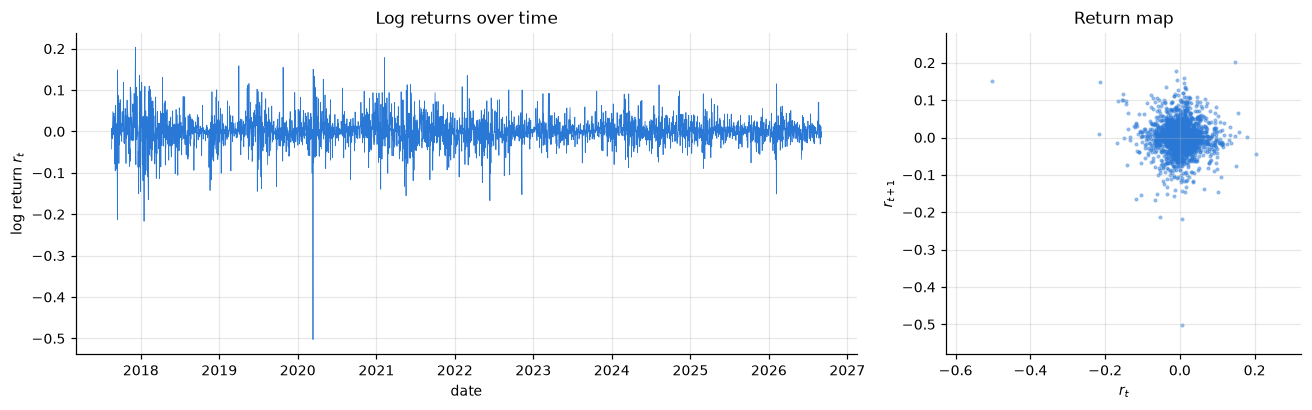

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(r.index, x, lw=0.5, color=BLUE)
ax[0].set(title="Log returns over time", xlabel="date", ylabel="log return $r_t$")
ax[1].scatter(x[:-1], x[1:], s=3, alpha=0.4, color=BLUE)
ax[1].set(title="Return map", xlabel="$r_t$", ylabel="$r_{t+1}$")
ax[1].set_aspect("equal", adjustable="datalim")
save(fig, "01_returns_and_return_map")

## 3. Time delay tau from Average Mutual Information

AMI(tau) measures how much knowing $r_t$ tells us about $r_{t+\tau}$ (linear and nonlinear dependence).
Standard rule: tau = first local minimum of AMI. For near-white series (most return series) AMI drops to its
noise floor at once and its "first minimum" is just a wiggle of that floor, so we also compute the first lag
where the autocorrelation falls below 1/e and take the **smaller** of the two (a rule tested on known chaotic
systems in the companion `chaos_markets` study).

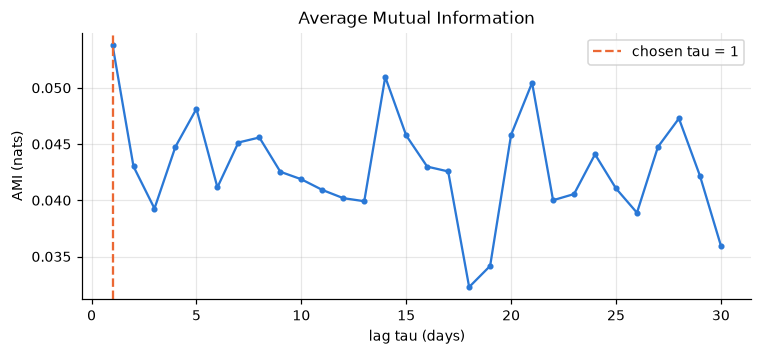

AMI first minimum: 3   ACF 1/e lag: 1   ->   tau = 1


In [5]:
def ami(series, max_lag=30, bins=16):
    edges = np.quantile(series, np.linspace(0, 1, bins + 1)); edges[-1] += 1e-12
    s = np.clip(np.searchsorted(edges, series, side="right") - 1, 0, bins - 1)
    out = []
    for lag in range(max_lag + 1):
        a, b = s[: len(s) - lag], s[lag:]
        joint = np.bincount(a * bins + b, minlength=bins * bins).reshape(bins, bins) / len(a)
        pa, pb = joint.sum(1), joint.sum(0)
        nz = joint > 0
        out.append(np.sum(joint[nz] * np.log(joint[nz] / np.outer(pa, pb)[nz])))
    return np.array(out)

def first_minimum(y):
    for i in range(1, len(y) - 1):
        if y[i] < y[i - 1] and y[i] <= y[i + 1]:
            return i
    return len(y) - 1

def acf_lag(series, level=1 / np.e, max_lag=30):
    s = series - series.mean(); v = s @ s
    for k in range(1, max_lag + 1):
        if abs(s[:-k] @ s[k:] / v) < level:
            return k
    return max_lag

A = ami(x, MAX_LAG_AMI)
tau_ami, tau_acf = first_minimum(A), acf_lag(x)
TAU = max(1, min(tau_ami, tau_acf))
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(range(1, MAX_LAG_AMI + 1), A[1:], "o-", ms=3, color=BLUE)
ax.axvline(TAU, color=ORANGE, ls="--", label=f"chosen tau = {TAU}")
ax.set(title="Average Mutual Information", xlabel="lag tau (days)", ylabel="AMI (nats)"); ax.legend()
save(fig, "02_ami")
print(f"AMI first minimum: {tau_ami}   ACF 1/e lag: {tau_acf}   ->   tau = {TAU}")

## 4. Embedding dimension m from False Nearest Neighbours

Build delay vectors $(r_t, r_{t+\tau}, \dots, r_{t+(m-1)\tau})$. If m is too small, points that are far apart
in the true state space look like neighbours ("false neighbours"); adding a dimension pulls them apart.
m = first dimension where the false-neighbour fraction drops below 5%. For deterministic systems it drops to
about 0 quickly; for noise it never does.

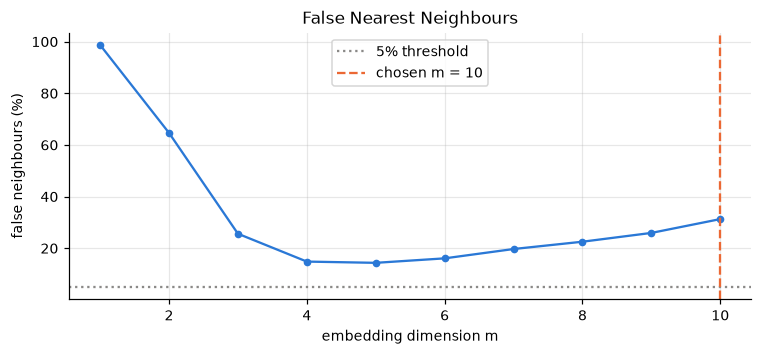

FNN (%) by m: [98.7 64.7 25.6 14.9 14.4 16.1 19.7 22.5 26.  31.3] 
-> m = 10  (threshold never reached: typical of noise)


In [6]:
def embed(series, m, tau):
    n = len(series) - (m - 1) * tau
    return np.column_stack([series[i * tau: i * tau + n] for i in range(m)])

def fnn(series, tau, m_max=10, rtol=15.0, atol=2.0, theiler=10):
    ra = np.std(series); out = []
    for m in range(1, m_max + 1):
        Y = embed(series, m + 1, tau); Ym = Y[:, :m]
        d, idx = cKDTree(Ym).query(Ym, k=2 * theiler + 3)
        false = valid = 0
        for i in range(len(Ym)):
            for dd, j in zip(d[i, 1:], idx[i, 1:]):
                if abs(j - i) > theiler and dd > 0:
                    extra = abs(Y[i, m] - Y[j, m])
                    false += (extra / dd > rtol) or (np.hypot(dd, extra) / ra > atol)
                    valid += 1
                    break
        out.append(false / max(valid, 1))
    return np.array(out)

THEILER = max(10, 2 * TAU)       # exclude temporal neighbours closer than this (in days)
F = fnn(x_std, TAU, M_MAX, theiler=THEILER)
below = np.where(F < 0.05)[0]
M = int(below[0] + 1) if len(below) else M_MAX
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(range(1, M_MAX + 1), F * 100, "o-", ms=4, color=BLUE)
ax.axhline(5, color=GREY, ls=":", label="5% threshold")
ax.axvline(M, color=ORANGE, ls="--", label=f"chosen m = {M}")
ax.set(title="False Nearest Neighbours", xlabel="embedding dimension m", ylabel="false neighbours (%)"); ax.legend()
save(fig, "03_fnn")
print("FNN (%) by m:", np.round(F * 100, 1), f"\n-> m = {M}" + ("  (threshold never reached: typical of noise)" if not len(below) else ""))

## 5. Phase-space reconstruction (2-d and 3-d) and recurrence plot

A chaotic attractor shows organised, folded geometry in these plots. Noise fills a blob.
The **recurrence plot** marks with a dot every pair of days (i, j) whose delay vectors are close
(threshold set so that 10% of pairs are close). Long diagonal lines mean the system repeats the same path
(determinism); periodic signals give evenly spaced diagonals; noise gives isolated dots.

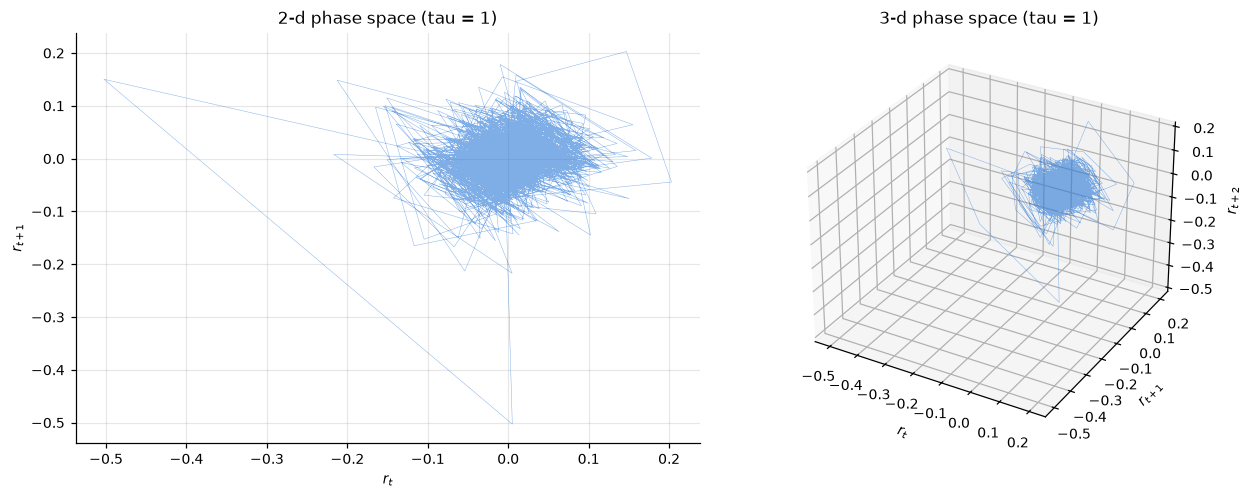

In [7]:
Y3 = embed(x, 3, TAU)
fig = plt.figure(figsize=(12, 4.6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(Y3[:, 0], Y3[:, 1], lw=0.3, color=BLUE, alpha=0.6)
ax1.set(title=f"2-d phase space (tau = {TAU})", xlabel="$r_t$", ylabel=f"$r_{{t+{TAU}}}$")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(Y3[:, 0], Y3[:, 1], Y3[:, 2], lw=0.3, color=BLUE, alpha=0.6)
ax2.set(title=f"3-d phase space (tau = {TAU})", xlabel="$r_t$", ylabel=f"$r_{{t+{TAU}}}$", zlabel=f"$r_{{t+{2*TAU}}}$")
save(fig, "04_phase_space")

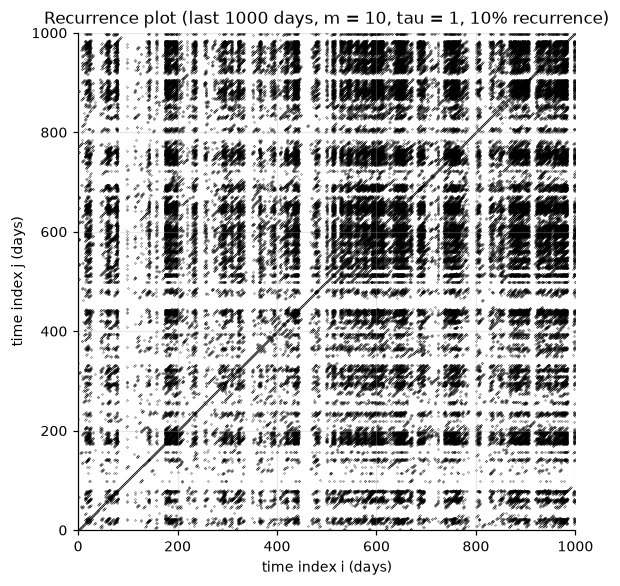

Recurrence determinism DET = 0.963


In [8]:
N_RP = 1000
Yr = embed(x_std, M, TAU)[-N_RP:]
Dm = np.max(np.abs(Yr[:, None, :] - Yr[None, :, :]), axis=-1)
eps = np.quantile(Dm[np.triu_indices(len(Yr), 1)], 0.10)
R = Dm <= eps
fig, ax = plt.subplots(figsize=(5.6, 5.4))
ii, jj = np.nonzero(R)
ax.scatter(ii, jj, s=0.05, color="black")
ax.set(title=f"Recurrence plot (last {N_RP} days, m = {M}, tau = {TAU}, 10% recurrence)",
       xlabel="time index i (days)", ylabel="time index j (days)", xlim=(0, N_RP), ylim=(0, N_RP))
ax.set_aspect("equal")
save(fig, "05_recurrence_plot")

def det_from_rp(R, lmin=2, theiler=1):
    """Share of recurrence points lying on diagonal lines of length >= lmin (DET)."""
    n = len(R); on_lines = total = 0
    for k in range(theiler + 1, n):
        d = np.diagonal(R, k).astype(int)
        total += d.sum()
        runs = np.diff(np.flatnonzero(np.diff(np.r_[0, d, 0])).reshape(-1, 2), axis=1).ravel()
        on_lines += runs[runs >= lmin].sum()
    return on_lines / max(total, 1)
print(f"Recurrence determinism DET = {det_from_rp(R):.3f}")

## 6. Largest Lyapunov exponent (Rosenstein method)

Take every point, find its nearest neighbour (excluding temporally close points), and follow both forward.
For chaos the average log distance grows **linearly** at first (slope = $\lambda_1 > 0$), then saturates.
Caution: for random series the curve also rises, so a positive slope alone proves nothing. We compare with
surrogates later.

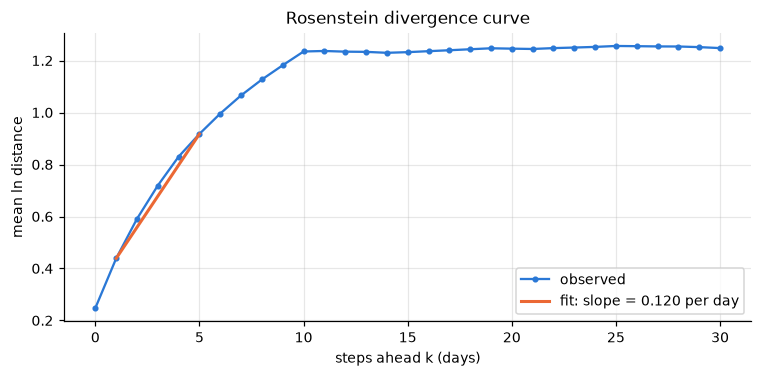

Largest Lyapunov exponent = 0.1198 per day (fit k = (1, 5), R^2 = 0.989)


In [9]:
def divergence(series, m, tau, theiler=10, steps=30):
    Y = embed(series, m, tau); n = len(Y) - steps
    d, idx = cKDTree(Y[:n]).query(Y[:n], k=2 * theiler + 12)
    nn = np.full(n, -1)
    for i in range(n):
        for dd, j in zip(d[i, 1:], idx[i, 1:]):
            if abs(j - i) > theiler and dd > 0:
                nn[i] = j; break
    i = np.where(nn >= 0)[0]; j = nn[i]
    return np.array([np.mean(np.log(np.linalg.norm(Y[i + k] - Y[j + k], axis=1) + 1e-300)) for k in range(steps + 1)])

def lyapunov(series, m, tau, theiler=10, steps=30):
    """Slope of the divergence curve over k = 1..k_sat, where k_sat is the first k reaching 60% of the total
    rise (at least 4 points). Returns slope per day, R^2 of the fit, the fit range and the curve."""
    cur = divergence(series, m, tau, theiler, steps)
    rise = cur.max() - cur[0]
    hit = np.where(cur - cur[0] >= 0.6 * rise)[0]
    k1 = max(int(hit[0]) if len(hit) else steps, 4)
    k = np.arange(1, k1 + 1)
    p = np.polyfit(k, cur[k], 1)
    r2 = 1 - np.var(cur[k] - np.polyval(p, k)) / np.var(cur[k])
    return p[0], r2, (1, k1), cur

LLE, LLE_R2, LLE_RANGE, LLE_CURVE = lyapunov(x_std, M, TAU, THEILER)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(LLE_CURVE, "o-", ms=3, color=BLUE, label="observed")
k = np.arange(LLE_RANGE[0], LLE_RANGE[1] + 1)
ax.plot(k, LLE_CURVE[k[0]] + LLE * (k - k[0]), color=ORANGE, lw=2, label=f"fit: slope = {LLE:.3f} per day")
ax.set(title="Rosenstein divergence curve", xlabel="steps ahead k (days)", ylabel="mean ln distance"); ax.legend()
save(fig, "06_lyapunov")
print(f"Largest Lyapunov exponent = {LLE:.4f} per day (fit k = {LLE_RANGE}, R^2 = {LLE_R2:.3f})")

## 7. Correlation dimension D2 (Grassberger-Procaccia)

$C(\varepsilon)$ = share of point pairs closer than $\varepsilon$. On an attractor $C(\varepsilon) \propto \varepsilon^{D_2}$.
We estimate the slope for m = 1..10. **Saturation** (D2 stops growing as m grows, at a small value) points to a
low-dimensional attractor. For noise D2 keeps rising with m.
Rule: D2 saturates if some run of three consecutive m has a spread below 15% of its mean and a mean below
(largest m of the run) - 1. Slope is the median local slope where $10^{-3} \le C \le 10^{-1}$.

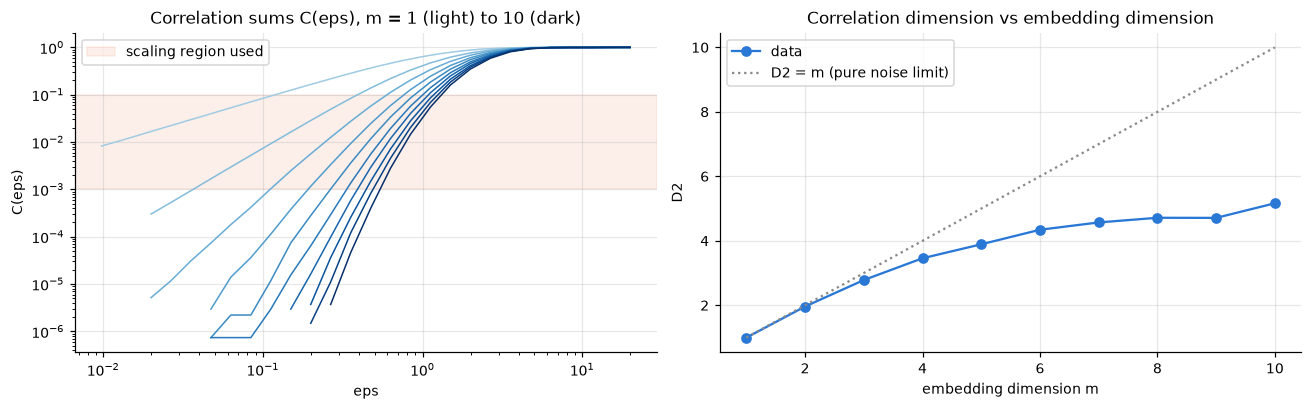

D2 by m: [1.   1.96 2.78 3.46 3.89 4.34 4.57 4.71 4.71 5.16] 
Saturated: True (D2 = 4.54)


In [10]:
def corr_sum(series, m, tau, theiler=10, n_max=2000, n_r=25):
    Y = embed(series, m, tau)
    step = int(np.ceil(len(Y) / n_max)); Y = Y[::step]
    th = max(1, int(np.ceil(theiler / step)))
    Dm = np.max(np.abs(Y[:, None, :] - Y[None, :, :]), axis=-1)
    iu = np.triu_indices(len(Y), th + 1)
    d = np.sort(Dm[iu])
    span = d[-1]
    radii = np.logspace(np.log10(span * 1e-3), np.log10(span), n_r)
    C = np.searchsorted(d, radii) / len(d)
    return radii, C

def d2_slope(radii, C):
    ok = C > 0
    lr, lc = np.log(radii[ok]), np.log(C[ok])
    sl = np.gradient(lc, lr)
    sel = (C[ok] >= 1e-3) & (C[ok] <= 1e-1)
    return float(np.median(sl[sel])) if sel.sum() >= 3 else np.nan

def correlation_dimension(series, tau, theiler=10, m_values=range(1, 11)):
    curves, d2 = {}, []
    for m in m_values:
        rr, C = corr_sum(series, m, tau, theiler)
        curves[m] = (rr, C); d2.append(d2_slope(rr, C))
    d2 = np.array(d2); ms = list(m_values)
    for i in range(len(d2) - 2):
        run = d2[i:i + 3]
        if np.all(np.isfinite(run)) and run.max() - run.min() <= 0.15 * run.mean() and run.mean() < ms[i + 2] - 1:
            return d2, True, float(run.mean()), curves
    return d2, False, np.nan, curves

D2_BY_M, D2_SAT, D2_VALUE, D2_CURVES = correlation_dimension(x_std, TAU, THEILER)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for m, (rr, C) in D2_CURVES.items():
    ax[0].loglog(rr, np.where(C > 0, C, np.nan), color=plt.cm.Blues(0.3 + 0.07 * m), lw=1)
ax[0].axhspan(1e-3, 1e-1, color=ORANGE, alpha=0.1, label="scaling region used")
ax[0].set(title="Correlation sums C(eps), m = 1 (light) to 10 (dark)", xlabel="eps", ylabel="C(eps)"); ax[0].legend()
ms = np.arange(1, 11)
ax[1].plot(ms, D2_BY_M, "o-", color=BLUE, label="data")
ax[1].plot(ms, ms, ":", color=GREY, label="D2 = m (pure noise limit)")
ax[1].set(title="Correlation dimension vs embedding dimension", xlabel="embedding dimension m", ylabel="D2"); ax[1].legend()
save(fig, "07_correlation_dimension")
print("D2 by m:", np.round(D2_BY_M, 2), "\nSaturated:", D2_SAT, f"(D2 = {D2_VALUE:.2f})" if D2_SAT else "")

## 8. The 0-1 test for chaos (Gottwald and Melbourne)

The series drives a 2-d walk $p(n) = \sum_j x_j \cos(jc)$, $q(n) = \sum_j x_j \sin(jc)$. For regular (periodic or
quasi-periodic) dynamics the walk stays bounded, $K \approx 0$; for chaos it spreads like diffusion, $K \approx 1$.
Important limitation: independent noise also gives $K \approx 1$, so K only separates "regular" from
"irregular", not chaos from noise. K is the median over 50 random frequencies c.

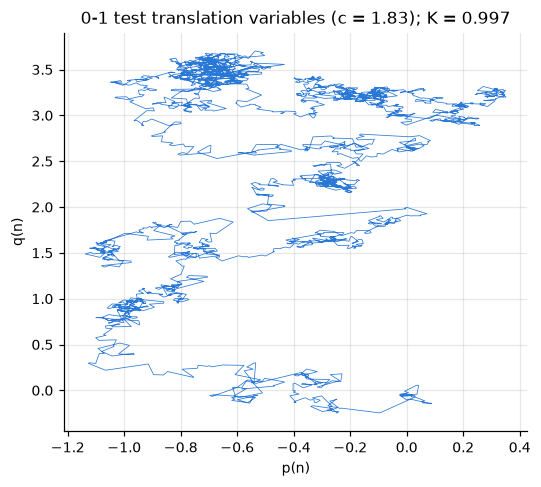

0-1 test: K = 0.997  (near 0: regular; near 1: irregular, i.e. chaos or noise)


In [11]:
def zero_one(series, n_c=50, seed=0):
    s = np.asarray(series, float) - np.mean(series)
    N = len(s); ncut = N // 10
    cs = np.random.default_rng(seed).uniform(np.pi / 5, 4 * np.pi / 5, n_c)
    j = np.arange(1, N + 1); n = np.arange(1, ncut + 1)
    Ks, pq = [], None
    for c in cs:
        p, q = np.cumsum(s * np.cos(j * c)), np.cumsum(s * np.sin(j * c))
        Mn = np.array([np.mean((p[k:] - p[:-k]) ** 2 + (q[k:] - q[:-k]) ** 2) for k in n])
        Ks.append(np.corrcoef(n, Mn)[0, 1])
        pq = pq or (p, q, c)
    return float(np.median(Ks)), pq

K01, (P01, Q01, C01) = zero_one(x)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(P01, Q01, lw=0.5, color=BLUE)
ax.set(title=f"0-1 test translation variables (c = {C01:.2f}); K = {K01:.3f}", xlabel="p(n)", ylabel="q(n)")
save(fig, "08_zero_one_test")
print(f"0-1 test: K = {K01:.3f}  (near 0: regular; near 1: irregular, i.e. chaos or noise)")

## 9. Surrogate data test

Surrogates are artificial series that keep some properties of the data but are random by construction.
If a statistic of the real series lies inside the surrogate distribution, that statistic gives **no evidence**
against the "just noise" explanation.

| Surrogate | Keeps | Removes |
|---|---|---|
| IAAFT | exact distribution (fat tails) and power spectrum (linear autocorrelation) | all nonlinear structure |
| GARCH(1,1)-t | fat tails and volatility clustering | any deterministic dynamics |

The GARCH family matters for returns: volatility clustering is nonlinear but random, and it can make returns
look different from IAAFT surrogates without any determinism.

Statistics compared (direction that would indicate deterministic structure):
- largest Lyapunov exponent (two-sided: any difference from noise),
- correlation dimension at m = 5 (lower than surrogates),
- 0-1 test K (two-sided),
- nonlinear prediction skill: out-of-sample correlation of a nearest-neighbour (simplex) forecast with the
  next value, trained on the first 70% (higher than surrogates).

In [12]:
def iaaft(series, rs, n_iter=200):
    amp = np.abs(np.fft.rfft(series)); srt = np.sort(series)
    s = rs.permutation(series)
    for _ in range(n_iter):
        s2 = np.fft.irfft(amp * np.exp(1j * np.angle(np.fft.rfft(s))), len(series))
        s_new = srt[np.argsort(np.argsort(s2))]
        if np.array_equal(s_new, s):
            break
        s = s_new
    return s

from arch import arch_model
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    g = arch_model(x / x.std(), mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
GP = g.params
print("GARCH(1,1)-t fit (unit-variance returns):", GP.round(4).to_dict())

def garch_sim(rs, n, burn=500):
    mu, w, a, b, nu = GP["mu"], GP["omega"], GP["alpha[1]"], GP["beta[1]"], max(GP["nu"], 2.05)
    z = stats.t.rvs(nu, size=n + burn, random_state=rs) / np.sqrt(nu / (nu - 2))
    s2, e = w / max(1 - a - b, 1e-3), np.empty(n + burn)
    for t in range(n + burn):
        e[t] = np.sqrt(s2) * z[t]
        s2 = w + a * e[t] ** 2 + b * s2
    return (mu + e[burn:]) * x.std()

def simplex_skill(series, m, tau, frac=0.7):
    Y = embed(series, m, tau)
    tgt = series[(m - 1) * tau + 1:]
    Y = Y[:len(tgt)]
    ntr = int(len(Y) * frac)
    d, idx = cKDTree(Y[:ntr]).query(Y[ntr:], k=m + 1)
    w = np.exp(-d / np.maximum(d[:, :1], 1e-12))
    pred = (w * tgt[:ntr][idx]).sum(1) / w.sum(1)
    return float(np.corrcoef(pred, tgt[ntr:])[0, 1])

def statistics(series):
    z = (series - series.mean()) / series.std()
    lle = lyapunov(z, M, TAU, THEILER)[0]
    rr, C = corr_sum(z, 5, TAU, THEILER)
    return {"lyapunov": lle, "D2_m5": d2_slope(rr, C), "K_01": zero_one(series, n_c=20)[0], "pred_skill": simplex_skill(z, M, TAU)}

DIRECTION = {"lyapunov": "two-sided", "D2_m5": "less", "K_01": "two-sided", "pred_skill": "greater"}
t0 = time.time()
OBS = statistics(x)
NULL = {}
for f_id, (fam, gen) in enumerate([("IAAFT", lambda rs: iaaft(x, rs)), ("GARCH", lambda rs: garch_sim(rs, len(x)))]):
    NULL[fam] = pd.DataFrame([statistics(gen(np.random.default_rng([SEED, f_id, i]))) for i in range(N_SURROGATES)])
print(f"surrogates done in {time.time() - t0:.0f} s")

def p_value(obs, null, direction):
    null = null[np.isfinite(null)]
    hi = (np.sum(null >= obs) + 1) / (len(null) + 1)
    lo = (np.sum(null <= obs) + 1) / (len(null) + 1)
    return hi if direction == "greater" else lo if direction == "less" else min(1.0, 2 * min(hi, lo))

rows = []
for st, dirn in DIRECTION.items():
    for fam, nd in NULL.items():
        nv = nd[st].values
        rows.append({"statistic": st, "surrogate": fam, "observed": OBS[st], "surrogate mean": np.nanmean(nv),
                     "surrogate 2.5%": np.nanquantile(nv, 0.025), "surrogate 97.5%": np.nanquantile(nv, 0.975),
                     "z": (OBS[st] - np.nanmean(nv)) / np.nanstd(nv, ddof=1), "p": p_value(OBS[st], nv, dirn),
                     "test": dirn})
SURR = pd.DataFrame(rows)
SURR["significant"] = SURR["p"] < ALPHA
SURR.round(4)

GARCH(1,1)-t fit (unit-variance returns): {'mu': 0.0207, 'omega': 0.0106, 'alpha[1]': 0.0725, 'beta[1]': 0.9275, 'nu': 3.199}


surrogates done in 97 s


,statistic,surrogate,observed,surrogate mean,surrogate 2.5%,surrogate 97.5%,z,p,test,significant
0,lyapunov,IAAFT,0.1198,0.1294,0.1229,0.1421,-2.0405,0.02,two-sided,True
1,lyapunov,GARCH,0.1198,0.1147,0.1074,0.1210,1.5182,0.16,two-sided,False
2,D2_m5,IAAFT,3.8922,4.1588,4.0402,4.2800,-4.2501,0.01,less,True
3,D2_m5,GARCH,3.8922,4.0625,3.7813,4.3175,-1.0317,0.19,less,False
4,K_01,IAAFT,0.9963,0.9971,0.9953,0.9985,-1.0128,0.36,two-sided,False
5,K_01,GARCH,0.9963,0.9968,0.9944,0.9990,-0.1278,0.50,two-sided,False
6,pred_skill,IAAFT,0.0540,0.0138,-0.0486,0.0658,1.2589,0.10,greater,False
7,pred_skill,GARCH,0.0540,-0.0017,-0.0924,0.0813,1.1720,0.15,greater,False


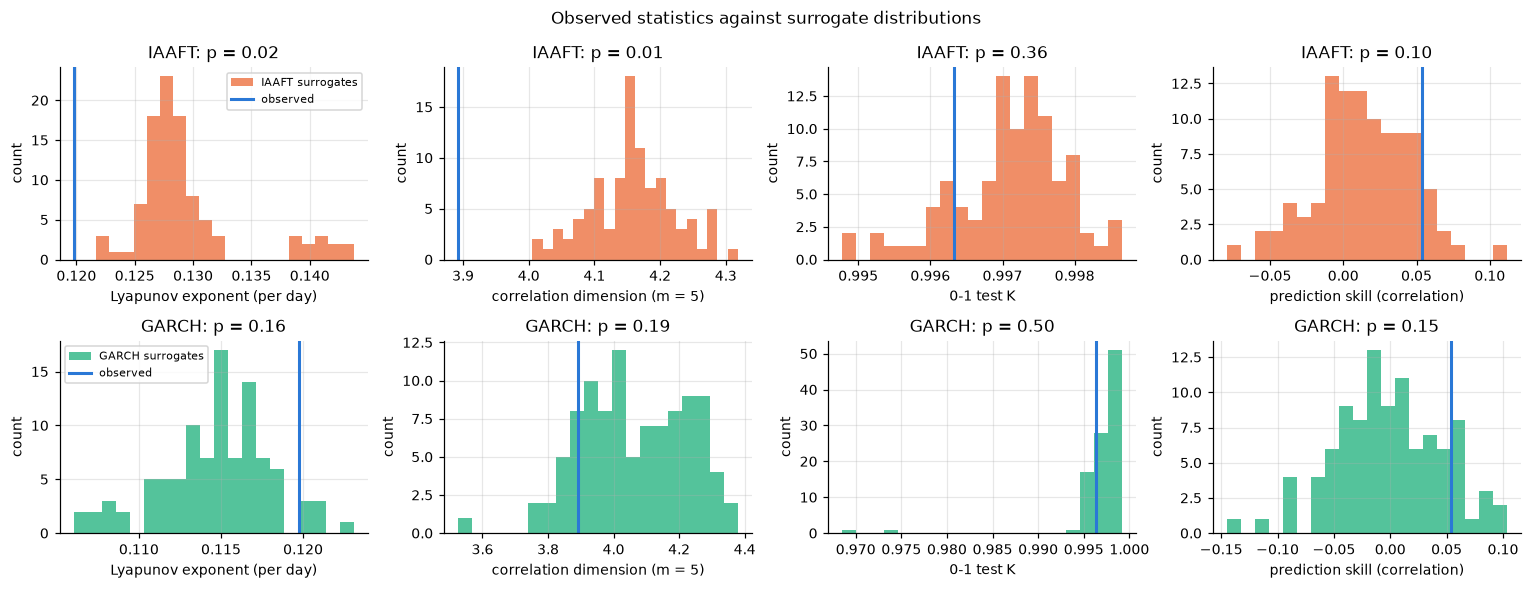

In [13]:
fig, ax = plt.subplots(2, 4, figsize=(14, 5.4))
labels = {"lyapunov": "Lyapunov exponent (per day)", "D2_m5": "correlation dimension (m = 5)",
          "K_01": "0-1 test K", "pred_skill": "prediction skill (correlation)"}
for row, fam in enumerate(NULL):
    for col, st in enumerate(DIRECTION):
        a = ax[row, col]
        a.hist(NULL[fam][st].dropna(), bins=20, color=ORANGE if fam == "IAAFT" else GREEN, alpha=0.75, label=f"{fam} surrogates")
        a.axvline(OBS[st], color=BLUE, lw=2, label="observed")
        p = SURR[(SURR.statistic == st) & (SURR.surrogate == fam)]["p"].iloc[0]
        a.set(title=f"{fam}: p = {p:.2f}", xlabel=labels[st], ylabel="count")
        if col == 0: a.legend(fontsize=7)
fig.suptitle("Observed statistics against surrogate distributions", fontsize=11)
save(fig, "09_surrogate_test")

## 10. Classification

Decision rule (written before seeing the results; evidence from several independent tests is required):

1. **Periodic**: K < 0.2 and D2 saturates below 0.5 (a closed orbit is a set of points or a curve).
2. **Quasi-periodic**: K < 0.2 and D2 saturates at 0.5 or more (a torus), with Lyapunov exponent not above surrogates.
3. **Potentially chaotic**: K > 0.8 **and** D2 saturates at a low value **and** the series differs from
   **both** surrogate families in the deterministic direction on at least two statistics (D2 lower and/or
   prediction skill higher, or a different Lyapunov exponent).
4. **Random/Stochastic**: K > 0.8, FNN never reaches 5%, and no statistic separates the data from the GARCH
   surrogates (everything is explained by a random process with fat tails and volatility clustering).
5. **Inconclusive**: anything else (mixed or weak evidence).

In [14]:
sig = {fam: SURR[(SURR.surrogate == fam) & SURR.significant]["statistic"].tolist() for fam in NULL}
det_dir = {}
for fam in NULL:
    s = SURR[SURR.surrogate == fam].set_index("statistic")
    det_dir[fam] = [st for st in ["D2_m5", "pred_skill", "lyapunov"] if s.loc[st, "significant"]]
both = sorted(set(det_dir["IAAFT"]) & set(det_dir["GARCH"]))
fnn_reached = len(below) > 0

if K01 < 0.2 and D2_SAT and D2_VALUE < 0.5:
    label = "Periodic"
elif K01 < 0.2 and D2_SAT:
    label = "Quasi-periodic"
elif K01 > 0.8 and D2_SAT and len(both) >= 2:
    label = "Potentially Chaotic"
elif K01 > 0.8 and not fnn_reached and len(det_dir["GARCH"]) == 0:
    label = "Random/Stochastic"
else:
    label = "Inconclusive"

evidence = pd.DataFrame([
    ("Time delay tau (AMI / ACF rule)", TAU, "chosen delay"),
    ("Embedding dimension m (FNN)", M, "5% reached" if fnn_reached else "FNN never below 5%: noise-like"),
    ("Recurrence DET", round(det_from_rp(R), 3), "compare with surrogates, not alone"),
    ("Largest Lyapunov exponent (per day)", round(LLE, 4), f"R^2 = {LLE_R2:.2f}; surrogates also positive"),
    ("Correlation dimension saturates?", "yes" if D2_SAT else "no",
     (f"D2 = {D2_VALUE:.2f}" + (" (high: finite-sample levelling, also seen in noise)" if D2_VALUE > 3 else "")) if D2_SAT else "D2 keeps growing with m"),
    ("0-1 test K", round(K01, 3), "near 1: irregular (chaos or noise)" if K01 > 0.8 else "near 0: regular" if K01 < 0.2 else "intermediate"),
    ("Statistics different from IAAFT", ", ".join(sig["IAAFT"]) or "none", "p < 0.05"),
    ("Statistics different from GARCH", ", ".join(sig["GARCH"]) or "none", "p < 0.05"),
], columns=["evidence", "value", "reading"])
print(evidence.to_string(index=False))
print(f"\nFINAL CLASSIFICATION: {label}")

                           evidence           value                                                       reading
    Time delay tau (AMI / ACF rule)               1                                                  chosen delay
        Embedding dimension m (FNN)              10                                FNN never below 5%: noise-like
                     Recurrence DET           0.963                            compare with surrogates, not alone
Largest Lyapunov exponent (per day)          0.1198                          R^2 = 0.99; surrogates also positive
   Correlation dimension saturates?             yes D2 = 4.54 (high: finite-sample levelling, also seen in noise)
                         0-1 test K           0.997                            near 1: irregular (chaos or noise)
    Statistics different from IAAFT lyapunov, D2_m5                                                      p < 0.05
    Statistics different from GARCH            none                                     

In [15]:
def explain():
    lines = [f"Series: {source}, {r.index[0].date()} to {r.index[-1].date()} (n = {len(r)})."]
    lines.append(f"The return map and phase portraits show {'no thin curve or folded structure' if label != 'Potentially Chaotic' else 'some structure'}; "
                 f"false nearest neighbours {'never fall below 5% up to m = ' + str(M_MAX) if not fnn_reached else 'fall below 5% at m = ' + str(M)}.")
    lyap_g = "it is not different from the GARCH surrogates" if "lyapunov" not in sig["GARCH"] else "it differs from the GARCH surrogates"
    lines.append(f"The Lyapunov exponent is {LLE:.3f} per day; the surrogates are positive too, and {lyap_g}, "
                 f"so a positive value is not evidence of chaos by itself.")
    if D2_SAT:
        d2_txt = (f"levels off at D2 = {D2_VALUE:.2f}; a value this high levels off for noise too, because about 3000 points "
                  f"cannot fill a high-dimensional space (at m = 5 the GARCH surrogates give {NULL['GARCH']['D2_m5'].mean():.2f} "
                  f"against {OBS['D2_m5']:.2f} for the data)") if D2_VALUE > 3 else f"saturates at a low value, D2 = {D2_VALUE:.2f}"
    else:
        d2_txt = "does not saturate (keeps growing with m)"
    lines.append(f"The correlation dimension {d2_txt}; the 0-1 test gives K = {K01:.2f}.")
    lines.append(f"Against IAAFT surrogates the data differ on: {', '.join(sig['IAAFT']) or 'nothing'}. "
                 f"Against GARCH surrogates: {', '.join(sig['GARCH']) or 'nothing'}.")
    if label == "Random/Stochastic":
        lines.append("Conclusion: the series is consistent with a random process with fat tails and volatility clustering. "
                     "Any difference from IAAFT surrogates is explained by volatility clustering, which GARCH reproduces. No evidence of deterministic chaos.")
    elif label == "Potentially Chaotic":
        lines.append("Conclusion: several independent tests point to low-dimensional deterministic structure beyond both noise models. "
                     "This is evidence worth investigating further, not proof of chaos.")
    elif label == "Inconclusive":
        lines.append("Conclusion: the tests do not agree. Some statistics separate the data from a noise model, but the combination required "
                     "for a chaos or a stochastic label is not met. Deterministic chaos is not claimed.")
    else:
        lines.append(f"Conclusion: the evidence matches {label.lower()} dynamics under the stated rule.")
    return "\n".join(lines)
print(explain())

Series: log returns of column 'close', 2017-08-18 to 2026-09-02 (n = 3303).
The return map and phase portraits show no thin curve or folded structure; false nearest neighbours never fall below 5% up to m = 10.
The Lyapunov exponent is 0.120 per day; the surrogates are positive too, and it is not different from the GARCH surrogates, so a positive value is not evidence of chaos by itself.
The correlation dimension levels off at D2 = 4.54; a value this high levels off for noise too, because about 3000 points cannot fill a high-dimensional space (at m = 5 the GARCH surrogates give 4.06 against 3.89 for the data); the 0-1 test gives K = 1.00.
Against IAAFT surrogates the data differ on: lyapunov, D2_m5. Against GARCH surrogates: nothing.
Conclusion: the series is consistent with a random process with fat tails and volatility clustering. Any difference from IAAFT surrogates is explained by volatility clustering, which GARCH reproduces. No evidence of deterministic chaos.


## 11. Power Spectrum Analysis of the returns

Does the return series contain periodic components (a sharp peak in the spectrum), long memory (a power law
$S(f) \propto f^{-\beta}$ at low frequencies) or more low-frequency power than a stochastic volatility model gives?
None of these would show chaos: a peak means periodicity, a power law means long memory or scaling, and a flat
broadband spectrum fits both noise and chaos. The comparison of all four series (returns, absolute and squared
returns, realised volatility) is in `volatility_chaos.ipynb`, section 10; this section covers returns only, with
the same settings and functions (`nla_tools.py`):

- standardised series, linear detrend; Welch (Hann, 512-day segments, 50% overlap) and the raw periodogram;
- frequency in cycles per day, period = 1 / frequency in days;
- slope fitted over periods 25 to 250 days, plus the GPH log-periodogram estimate over the lowest $\sqrt{n}$ frequencies;
- 999 IAAFT and 999 GARCH(1,1)-t surrogates. IAAFT keeps the spectrum by construction (consistency check only);
  GARCH is the informative comparison.

surrogate spectra: 30 s


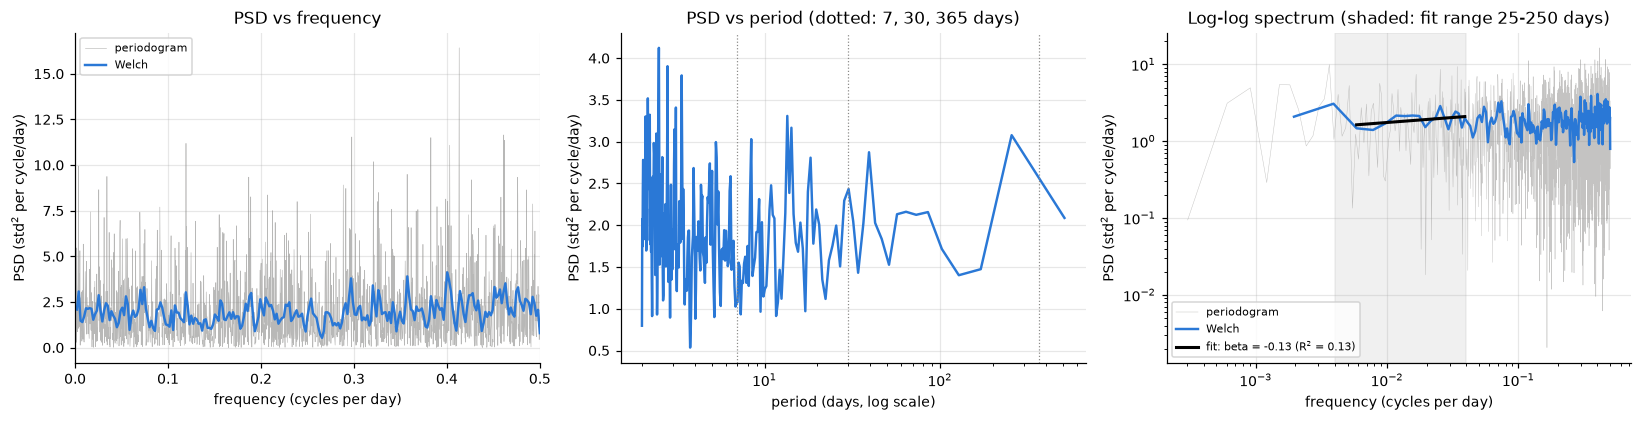

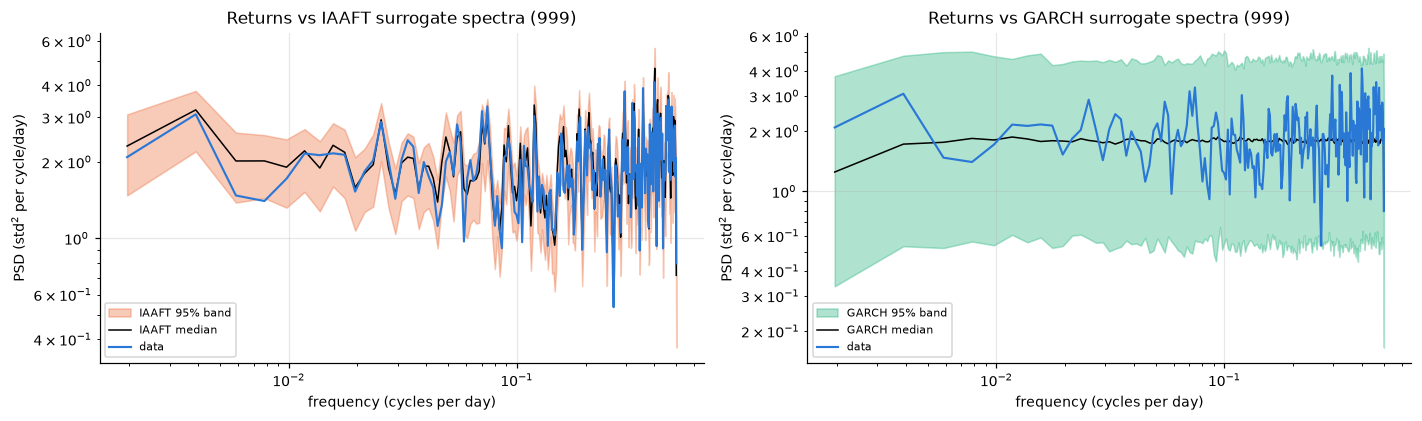

In [16]:
import nla_tools as T
PSD_DIR = FIG / "power_spectrum_returns"; PSD_DIR.mkdir(parents=True, exist_ok=True)
N_PSD = 999

def save_psd(fig, name):
    fig.tight_layout()
    fig.savefig(PSD_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

GARCH_T = T.Garch(x)
f_w, P_w = T.psd_welch(x)
f_p, P_p = T.psd_periodogram(x)
t0 = time.time()
SP = T.surrogate_spectra(lambda rr: {"returns": rr}, x, "returns", GARCH_T, N_PSD, SEED)
print(f"surrogate spectra: {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
ax[0].plot(f_p, P_p, lw=0.4, color=GREY, alpha=0.6, label="periodogram")
ax[0].plot(f_w, P_w, lw=1.6, color=BLUE, label="Welch")
ax[0].set(title="PSD vs frequency", xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)", xlim=(0, 0.5))
ax[0].legend(fontsize=7)
ax[1].semilogx(1 / f_w, P_w, lw=1.6, color=BLUE)
for d_ in [7, 30, 365]:
    ax[1].axvline(d_, color=GREY, ls=":", lw=0.8)
ax[1].set(title="PSD vs period (dotted: 7, 30, 365 days)", xlabel="period (days, log scale)", ylabel="PSD (std$^2$ per cycle/day)")
beta, se, r2, npts = T.spectral_slope(f_w, P_w)
d, d_se, m_gph, beta_gph = T.gph(x)
sel = (f_w >= T.SLOPE_RANGE[0]) & (f_w <= T.SLOPE_RANGE[1])
c = np.mean(np.log10(P_w[sel]) + beta * np.log10(f_w[sel]))
ax[2].loglog(f_p, P_p, lw=0.3, color=GREY, alpha=0.5, label="periodogram")
ax[2].loglog(f_w, P_w, lw=1.6, color=BLUE, label="Welch")
ax[2].loglog(f_w[sel], 10 ** c * f_w[sel] ** (-beta), color="black", lw=2, label=f"fit: beta = {beta:.2f} (R$^2$ = {r2:.2f})")
ax[2].axvspan(*T.SLOPE_RANGE, color=GREY, alpha=0.12)
ax[2].set(title="Log-log spectrum (shaded: fit range 25-250 days)", xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)")
ax[2].legend(fontsize=7)
save_psd(fig, "01_returns_psd")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for a, kind, col in [(ax[0], "iaaft", ORANGE), (ax[1], "garch", GREEN)]:
    lo, med, hi = np.quantile(SP[kind]["P"], [0.025, 0.5, 0.975], axis=0)
    a.fill_between(f_w, lo, hi, color=col, alpha=0.35, label=f"{kind.upper()} 95% band")
    a.loglog(f_w, med, color="black", lw=1, label=f"{kind.upper()} median")
    a.loglog(f_w, P_w, color=BLUE, lw=1.4, label="data")
    a.set(title=f"Returns vs {kind.upper()} surrogate spectra ({N_PSD})", xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)")
    a.legend(fontsize=7)
save_psd(fig, "02_returns_psd_vs_surrogates")

In [17]:
lo_sh, hi_sh = T.band_shares(f_w, P_w)
g = SP["garch"]
p_glob_g, _, out_g = T.envelope_test(P_w, g["P"])
p_glob_i, _, out_i = T.envelope_test(P_w, SP["iaaft"]["P"])
iw = int(np.argmin(np.abs(f_w - 1 / 7)))
hi97 = np.quantile(g["P"], 0.975, axis=0)
peaks = T.spectral_peaks(f_w, P_w)
PSD_RET = pd.DataFrame([
    ("spectral exponent beta (Welch, periods 25-250 d)", f"{beta:.3f} (s.e. {se:.3f}, R^2 {r2:.3f}, {npts} points)"),
    ("beta of GARCH surrogates, median [95%]", f"{np.median(g['beta']):.2f} [{np.quantile(g['beta'], 0.025):.2f}, {np.quantile(g['beta'], 0.975):.2f}]"),
    ("p beta vs GARCH (two-sided)", round(T.p_value(beta, g["beta"], "two-sided"), 3)),
    ("beta GPH = 2d (s.e.), lowest m frequencies", f"{beta_gph:.3f} ({2 * d_se:.3f}), m = {m_gph}"),
    ("share of power at periods > 20 d (white noise about 0.10)", round(lo_sh, 3)),
    ("p low-band share vs GARCH (two-sided)", round(T.p_value(lo_sh, g["low"], "two-sided"), 3)),
    ("share of power at periods < 5 d", round(hi_sh, 3)),
    ("top peaks (period)", "; ".join(f"{per:.1f} d" + (" (above GARCH 97.5% band)" if P_ > hi97[np.argmin(np.abs(f_w - fr))] else "") for fr, per, P_ in peaks)),
    ("p weekly component (7 d) vs GARCH (one-sided)", round(T.p_value(P_w[iw], g["P"][:, iw], "greater"), 3)),
    ("global test p vs GARCH / share outside band", f"{p_glob_g:.3f} / {out_g:.3f}"),
    ("global test p vs IAAFT / share outside band", f"{p_glob_i:.3f} / {out_i:.3f}"),
], columns=["statistic", "value"])
PSD_RET.to_csv(PSD_DIR / "returns_power_spectrum_summary.csv", index=False)
print(PSD_RET.to_string(index=False))
print("\nReading: a single peak above the pointwise band is expected by chance among 256 frequencies (about 6 at 2.5%);"
      " a periodic component would need the global test to reject as well. beta near 0 means a flat (white) spectrum:"
      " no long memory in returns.")

                                                statistic                                     value
         spectral exponent beta (Welch, periods 25-250 d) -0.130 (s.e. 0.084, R^2 0.130, 18 points)
                   beta of GARCH surrogates, median [95%]                        0.00 [-0.61, 0.70]
                              p beta vs GARCH (two-sided)                                     0.632
               beta GPH = 2d (s.e.), lowest m frequencies                    -0.060 (0.170), m = 57
share of power at periods > 20 d (white noise about 0.10)                                     0.092
                    p low-band share vs GARCH (two-sided)                                     0.992
                          share of power at periods < 5 d                                      0.63
                                       top peaks (period)                       2.5 d; 2.8 d; 3.4 d
            p weekly component (7 d) vs GARCH (one-sided)                                     0.848
